# Additional Report

In this notebook, I solve four follow-up tasks for TRIK motors **M3** and **M4** ($U_{\text{battery}} = 11.7\text{ V}$):
1. Identify the motor parameters on all 3 signal types (**Step**, **Square Wave**, and **Chirp**).
2. Build a dead-zone compensation function using `min()` and `max()` so small commands still move the robot.
3. Add Coulomb friction to the motor equation and find the voltage that cancels it out.
4. Build a compensation function for backward–forward asymmetry.


In [1]:
import os
import glob
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit, least_squares
import matplotlib.pyplot as plt

try:
    get_ipython().run_line_magic('matplotlib', 'inline')
except Exception:
    pass

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10
plt.rcParams['lines.linewidth'] = 1.8
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

# Locate motor_data folder
for folder in ['motor_data', 'CS413 - Robotics/Lab5/motor_data', 'public/assets/aistudio']:
    if os.path.exists(folder):
        DATA_DIR = folder
        break
else:
    raise FileNotFoundError("Could not find motor_data folder!")

U_battery = 11.7
batt_file = os.path.join(DATA_DIR, 'battery.txt')
if os.path.exists(batt_file):
    with open(batt_file) as f:
        for line in f:
            if line.startswith('battery_mean_V='):
                U_battery = float(line.split('=')[1].strip())

def get_file(prefix):
    if prefix == 'steps_M4':
        hits = glob.glob(os.path.join(DATA_DIR, 'steps_M4_12d1c544*'))
        if hits:
            return hits[0]
    hits = glob.glob(os.path.join(DATA_DIR, f'{prefix}*'))
    return hits[0]

def load_data(file_path):
    raw = np.loadtxt(file_path, delimiter=',')
    t = (raw[:, 1] - raw[0, 1]) / 1000.0
    theta = (raw[:, 0] - raw[0, 0]) * np.pi / 180.0
    pwm = raw[:, 2]
    volts = (pwm / 100.0) * U_battery
    omega = pd.Series(np.gradient(theta, t)).rolling(5, center=True, min_periods=1).mean().values
    return t, theta, omega, pwm, volts

def fit_percent(y_real, y_model):
    denom = np.linalg.norm(y_real - np.mean(y_real))
    return 0.0 if denom < 1e-9 else 100.0 * (1.0 - np.linalg.norm(y_real - y_model) / denom)

def rmse(y_real, y_model):
    return float(np.sqrt(np.mean((y_real - y_model) ** 2)))

print(f"Loaded data from: {DATA_DIR} (U_battery = {U_battery:.1f} V)")


Loaded data from: CS413 - Robotics/Lab5/motor_data (U_battery = 11.7 V)


---
## 1. Motor Identification on All 3 Signal Types (M3 & M4)

We have three types of experiments for both **M3** and **M4**:
* **Step Series** (`steps_M3`, `steps_M4`, `steps_M4_repeat`): tests steady speed at each PWM level.
* **Square Wave** (`square_M3`, `square_M4`): switches fast between $+60\%$ and $-60\%$ PWM.
* **Chirp** (`chirp_M3`, `chirp_M4`): sweeps frequency from $0.2\text{ Hz}$ to $3.0\text{ Hz}$ at $\pm 60\%$ PWM.

Testing all three signals lets us check if the same parameters ($T_m$, $k_e$, and friction $U_c$) work not only on steady steps, but also when the motor reverses quickly or oscillates at high frequency.


M3         | Avg Step Fit: 99.44% | Tm (fwd/bwd): 0.138s / 0.112s | ke @60% (fwd/bwd): 0.630 / 0.662
M4         | Avg Step Fit: 99.52% | Tm (fwd/bwd): 0.125s / 0.122s | ke @60% (fwd/bwd): 0.698 / 0.763
M4 Repeat  | Avg Step Fit: 99.22% | Tm (fwd/bwd): 0.115s / 0.117s | ke @60% (fwd/bwd): 0.689 / 0.763


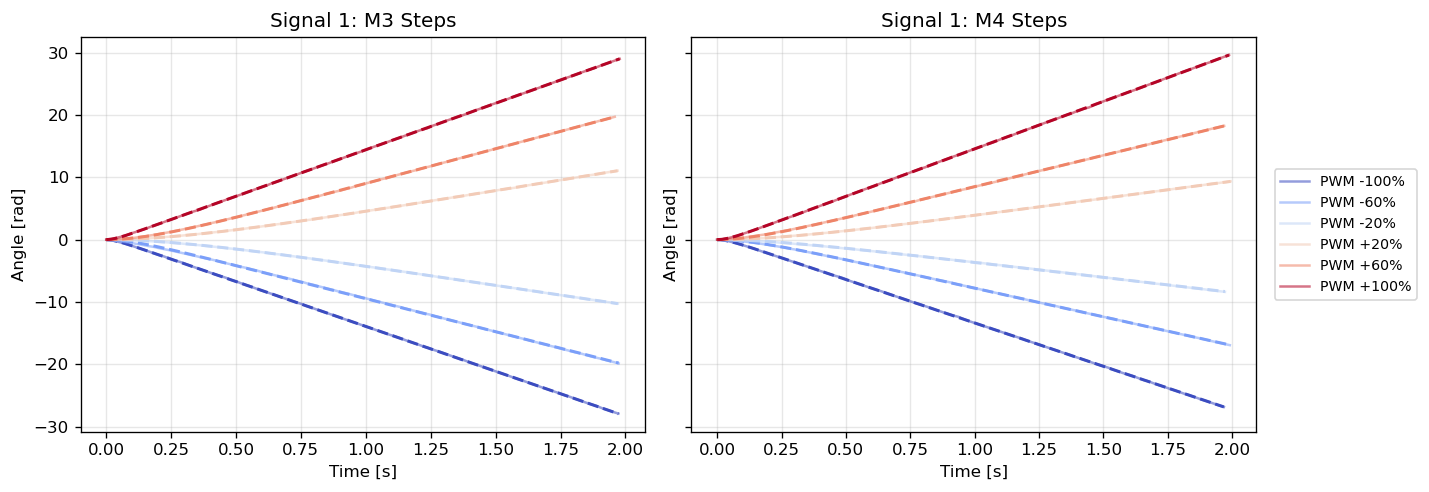

In [2]:
# --- Signal 1: Step Series ---
def step_model(t, omega_ss, Tm):
    Tm_s = np.maximum(Tm, 1e-4)
    return omega_ss * (t - Tm_s + Tm_s * np.exp(-t / Tm_s))

def fit_steps(file_path):
    raw = np.loadtxt(file_path, delimiter=',')
    ang, t_ms, pwm = raw[:, 0], raw[:, 1], raw[:, 2]
    cuts = np.where(np.diff(pwm) != 0)[0] + 1
    rows, segs = [], []
    for idx in np.split(np.arange(len(pwm)), cuts):
        p = int(pwm[idx[0]])
        if p == 0:
            continue
        t_s = (t_ms[idx] - t_ms[idx[0]]) / 1000.0
        th_s = (ang[idx] - ang[idx[0]]) * np.pi / 180.0
        popt, _ = curve_fit(step_model, t_s, th_s, p0=[th_s[-1] / t_s[-1], 0.10],
                            bounds=([-50.0, 0.005], [50.0, 1.0]), maxfev=10000)
        w_ss, Tm = popt
        u_v = (p / 100.0) * U_battery
        th_fit = step_model(t_s, w_ss, Tm)
        rows.append({'PWM': p, 'omega_ss': w_ss, 'Tm': Tm, 'ke': u_v / w_ss, 'fit': fit_percent(th_s, th_fit)})
        segs.append({'PWM': p, 't': t_s, 'th_real': th_s, 'th_fit': th_fit})
    return pd.DataFrame(rows), segs

df_step_M3, seg_M3 = fit_steps(get_file('steps_M3'))
df_step_M4, seg_M4 = fit_steps(get_file('steps_M4'))
df_step_M4_rep, _  = fit_steps(get_file('steps_M4_repeat'))

for name, df in [('M3', df_step_M3), ('M4', df_step_M4), ('M4 Repeat', df_step_M4_rep)]:
    ke_f = df.loc[df['PWM'] == 60, 'ke'].values[0]
    ke_b = df.loc[df['PWM'] == -60, 'ke'].values[0]
    tm_f = df.loc[df['PWM'] >= 40, 'Tm'].mean()
    tm_b = df.loc[df['PWM'] <= -40, 'Tm'].mean()
    print(f"{name:10s} | Avg Step Fit: {df['fit'].mean():.2f}% | Tm (fwd/bwd): {tm_f:.3f}s / {tm_b:.3f}s | ke @60% (fwd/bwd): {ke_f:.3f} / {ke_b:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
sample_pwms = [-100, -60, -20, 20, 60, 100]
cols = plt.cm.coolwarm(np.linspace(0, 1, len(sample_pwms)))

for ax, segs, title in zip(axes, [seg_M3, seg_M4], ['Signal 1: M3 Steps', 'Signal 1: M4 Steps']):
    for p, c in zip(sample_pwms, cols):
        s = next(x for x in segs if x['PWM'] == p)
        ax.plot(s['t'], s['th_real'], color=c, alpha=0.55, lw=1.5, label=f"PWM {p:+d}%")
        ax.plot(s['t'], s['th_fit'], '--', color=c, lw=1.8)
    ax.set_title(title)
    ax.set_xlabel('Time [s]')
    ax.set_ylabel('Angle [rad]')
axes[1].legend(loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize=8.5)
plt.tight_layout()
plt.show()


In [3]:
# --- Motor Simulator & Fitter for Square Wave and Chirp ---
def simulate_motor(t, u_volts, Tm_fwd, Tm_bwd, ke_fwd, ke_bwd, Uc_fwd=0.0, Uc_bwd=0.0):
    w = np.zeros(len(t))
    th = np.zeros(len(t))
    for k in range(len(t) - 1):
        dt = t[k + 1] - t[k]
        u_mid = 0.5 * (u_volts[k] + u_volts[k + 1])
        wk = w[k]

        # Apply direction-specific parameters and subtract Coulomb friction Uc
        if abs(wk) < 0.05:
            if u_mid > Uc_fwd:
                u_eff, Tm, ke = u_mid - Uc_fwd, Tm_fwd, ke_fwd
            elif u_mid < -Uc_bwd:
                u_eff, Tm, ke = u_mid + Uc_bwd, Tm_bwd, ke_bwd
            else:
                u_eff, Tm, ke = 0.0, Tm_fwd, ke_fwd
        else:
            if wk > 0:
                u_eff, Tm, ke = u_mid - Uc_fwd, Tm_fwd, ke_fwd
            else:
                u_eff, Tm, ke = u_mid + Uc_bwd, Tm_bwd, ke_bwd

        a = np.exp(-dt / max(Tm, 1e-4))
        w_next = wk * a + (u_eff / ke) * (1.0 - a)
        if abs(u_mid) <= max(Uc_fwd, Uc_bwd) and (wk * w_next < 0):
            w_next = 0.0

        w[k + 1] = w_next
        th[k + 1] = th[k] + 0.5 * (wk + w_next) * dt
    return w, th

def fit_signal(file_path):
    t, th, w, pwm, u = load_data(file_path)

    # Basic linear fit (same forward/backward, no friction)
    def err_lin(p):
        ws, ths = simulate_motor(t, u, p[0], p[0], p[1], p[1], 0.0, 0.0)
        return np.concatenate([ths - th, 0.5 * (ws - w)])

    res_lin = least_squares(err_lin, [0.15, 0.65], bounds=([0.01, 0.2], [0.5, 2.0]))
    Tm_l, ke_l = res_lin.x
    w_l, th_l = simulate_motor(t, u, Tm_l, Tm_l, ke_l, ke_l, 0.0, 0.0)

    # Full fit (directional Tm, ke + Coulomb friction Uc)
    def err_full(p):
        ws, ths = simulate_motor(t, u, p[0], p[1], p[2], p[3], p[4], p[5])
        return np.concatenate([ths - th, 0.5 * (ws - w)])

    best = None
    for x0 in ([0.09, 0.10, 0.65, 0.72, 0.20, 0.45], [0.15, 0.16, 0.65, 0.72, 0.02, 0.25]):
        cand = least_squares(err_full, x0, bounds=([0.02, 0.02, 0.2, 0.2, 0.0, 0.0], [0.5, 0.5, 2.0, 2.0, 2.0, 2.0]))
        if best is None or cand.cost < best.cost:
            best = cand
    Tm_f, Tm_b, ke_f, ke_b, Uc_f, Uc_b = best.x
    w_f, th_f = simulate_motor(t, u, Tm_f, Tm_b, ke_f, ke_b, Uc_f, Uc_b)

    return {
        't': t, 'pwm': pwm, 'u': u, 'th': th, 'w': w,
        'Tm_lin': Tm_l, 'ke_lin': ke_l, 'th_lin': th_l, 'w_lin': w_l,
        'Tm_f': Tm_f, 'Tm_b': Tm_b, 'ke_f': ke_f, 'ke_b': ke_b, 'Uc_f': Uc_f, 'Uc_b': Uc_b,
        'th_full': th_f, 'w_full': w_f,
        'fit_th_lin': fit_percent(th, th_l), 'fit_w_lin': fit_percent(w, w_l),
        'fit_th_full': fit_percent(th, th_f), 'fit_w_full': fit_percent(w, w_f),
        'rmse_th_full': rmse(th, th_f), 'rmse_w_full': rmse(w, w_f)
    }

sq_M3 = fit_signal(get_file('square_M3'))
sq_M4 = fit_signal(get_file('square_M4'))
ch_M3 = fit_signal(get_file('chirp_M3'))
ch_M4 = fit_signal(get_file('chirp_M4'))


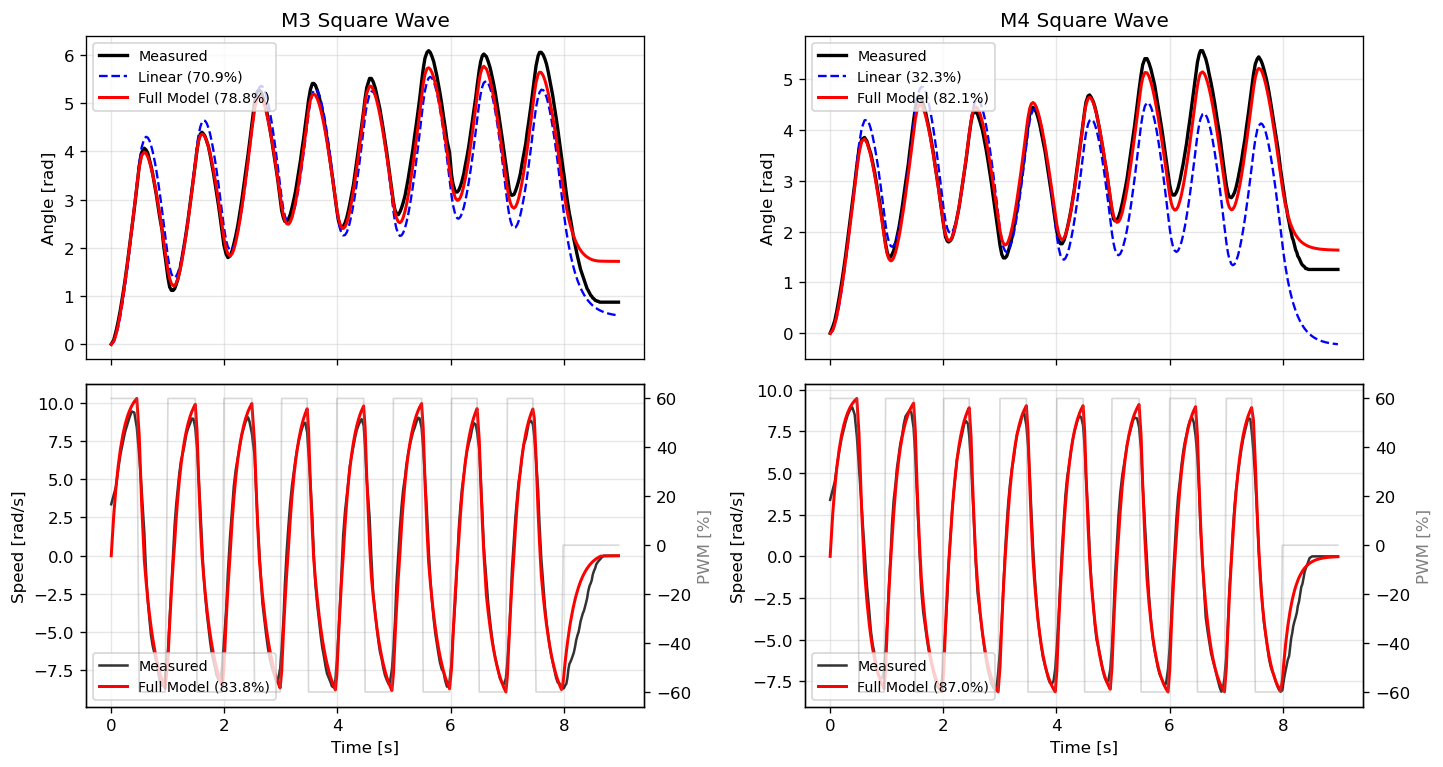

In [4]:
# --- Signal 2: Square Wave (M3 & M4) ---
fig, axes = plt.subplots(2, 2, figsize=(12, 6.5), sharex=True)
for col, (name, r) in enumerate([('M3 Square Wave', sq_M3), ('M4 Square Wave', sq_M4)]):
    ax1, ax2 = axes[0, col], axes[1, col]
    ax1.plot(r['t'], r['th'], 'k-', lw=2.0, label='Measured')
    ax1.plot(r['t'], r['th_lin'], 'b--', lw=1.4, label=f"Linear ({r['fit_th_lin']:.1f}%)")
    ax1.plot(r['t'], r['th_full'], 'r-', lw=1.8, label=f"Full Model ({r['fit_th_full']:.1f}%)")
    ax1.set_title(name)
    ax1.set_ylabel('Angle [rad]')
    ax1.legend(loc='upper left', fontsize=8.5)

    ax2.plot(r['t'], r['w'], 'k-', lw=1.5, alpha=0.8, label='Measured')
    ax2.plot(r['t'], r['w_full'], 'r-', lw=1.8, label=f"Full Model ({r['fit_w_full']:.1f}%)")
    ax2_p = ax2.twinx()
    ax2_p.plot(r['t'], r['pwm'], color='gray', alpha=0.3, lw=1.0)
    ax2_p.set_ylabel('PWM [%]', color='gray')
    ax2_p.grid(False)
    ax2.set_xlabel('Time [s]')
    ax2.set_ylabel('Speed [rad/s]')
    ax2.legend(loc='lower left', fontsize=8.5)

plt.tight_layout()
plt.show()


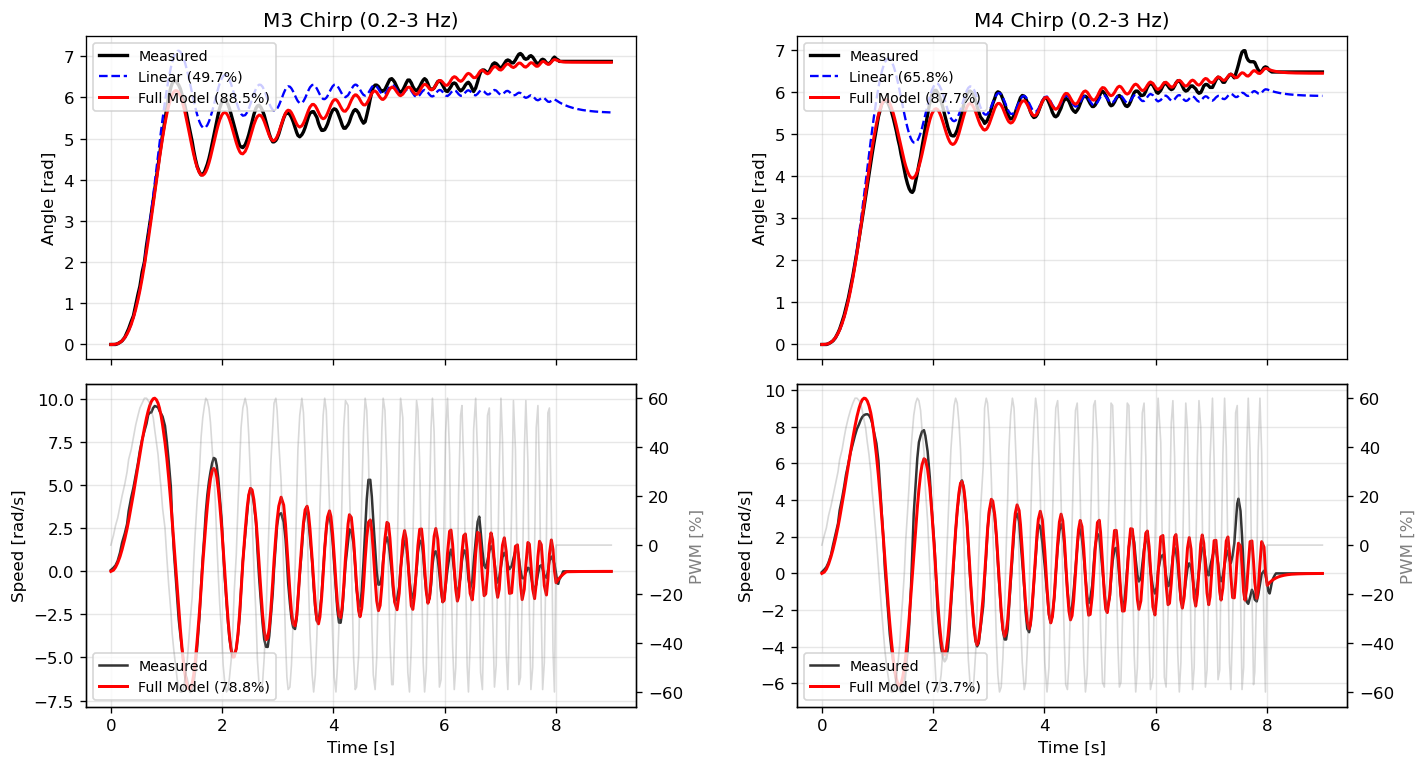

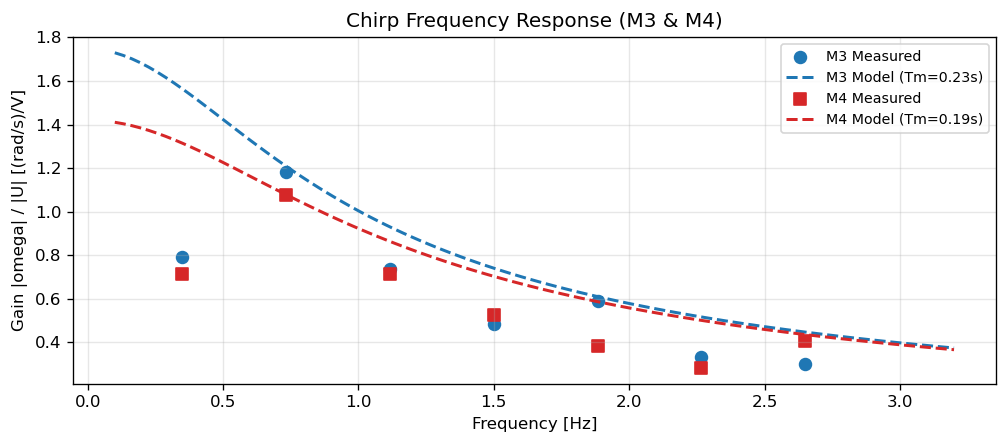

In [5]:
# --- Signal 3: Chirp & Frequency Response (M3 & M4) ---
fig, axes = plt.subplots(2, 2, figsize=(12, 6.5), sharex=True)
for col, (name, r) in enumerate([('M3 Chirp (0.2-3 Hz)', ch_M3), ('M4 Chirp (0.2-3 Hz)', ch_M4)]):
    ax1, ax2 = axes[0, col], axes[1, col]
    ax1.plot(r['t'], r['th'], 'k-', lw=2.0, label='Measured')
    ax1.plot(r['t'], r['th_lin'], 'b--', lw=1.4, label=f"Linear ({r['fit_th_lin']:.1f}%)")
    ax1.plot(r['t'], r['th_full'], 'r-', lw=1.8, label=f"Full Model ({r['fit_th_full']:.1f}%)")
    ax1.set_title(name)
    ax1.set_ylabel('Angle [rad]')
    ax1.legend(loc='upper left', fontsize=8.5)

    ax2.plot(r['t'], r['w'], 'k-', lw=1.5, alpha=0.8, label='Measured')
    ax2.plot(r['t'], r['w_full'], 'r-', lw=1.8, label=f"Full Model ({r['fit_w_full']:.1f}%)")
    ax2_p = ax2.twinx()
    ax2_p.plot(r['t'], r['pwm'], color='gray', alpha=0.3, lw=1.0)
    ax2_p.set_ylabel('PWM [%]', color='gray')
    ax2_p.grid(False)
    ax2.set_xlabel('Time [s]')
    ax2.set_ylabel('Speed [rad/s]')
    ax2.legend(loc='lower left', fontsize=8.5)

plt.tight_layout()
plt.show()

# Frequency response (amplitude ratio vs frequency) for M3 and M4
fig, ax = plt.subplots(figsize=(8.5, 3.8))
f_bins = np.linspace(0.35, 2.65, 7)
f_line = np.linspace(0.1, 3.2, 100)

for name, r, col, mk in [('M3', ch_M3, '#1f77b4', 'o'), ('M4', ch_M4, '#d62728', 's')]:
    inst_f = 0.2 + (3.0 - 0.2) * (r['t'] / 8.0)
    gains, freqs = [], []
    for fc in f_bins:
        mask = (inst_f >= fc - 0.25) & (inst_f <= fc + 0.25) & (r['t'] <= 8.0)
        if np.sum(mask) > 8:
            w_amp = 0.5 * (np.max(r['w'][mask]) - np.min(r['w'][mask]))
            u_amp = 0.5 * (np.max(r['u'][mask]) - np.min(r['u'][mask]))
            if u_amp > 0.5:
                gains.append(w_amp / u_amp)
                freqs.append(fc)
    ke_avg = 0.5 * (r['ke_f'] + r['ke_b'])
    Tm_avg = 0.5 * (r['Tm_f'] + r['Tm_b'])
    ax.scatter(freqs, gains, color=col, marker=mk, s=50, label=f"{name} Measured")
    ax.plot(f_line, 1.0 / (ke_avg * np.sqrt(1.0 + (2.0 * np.pi * f_line * Tm_avg) ** 2)), '--', color=col, label=f"{name} Model (Tm={Tm_avg:.2f}s)")

ax.set_title('Chirp Frequency Response (M3 & M4)')
ax.set_xlabel('Frequency [Hz]')
ax.set_ylabel('Gain |omega| / |U| [(rad/s)/V]')
ax.legend(fontsize=8.5)
plt.tight_layout()
plt.show()


In [6]:
# Comparison across all 3 signal types
summary = pd.DataFrame([
    {'Motor': 'M3', 'Signal': '1. Step Series',
     'Tm (fwd / bwd) [s]': f"{df_step_M3.loc[df_step_M3['PWM']>=40,'Tm'].mean():.3f} / {df_step_M3.loc[df_step_M3['PWM']<=-40,'Tm'].mean():.3f}",
     'ke (fwd / bwd) [V*s/rad]': f"{df_step_M3.loc[df_step_M3['PWM']==60,'ke'].values[0]:.3f} / {df_step_M3.loc[df_step_M3['PWM']==-60,'ke'].values[0]:.3f}",
     'Angle Fit': f"{df_step_M3['fit'].mean():.1f}%", 'Speed Fit': '-'},
    {'Motor': 'M3', 'Signal': '2. Square Wave',
     'Tm (fwd / bwd) [s]': f"{sq_M3['Tm_f']:.3f} / {sq_M3['Tm_b']:.3f}",
     'ke (fwd / bwd) [V*s/rad]': f"{sq_M3['ke_f']:.3f} / {sq_M3['ke_b']:.3f}",
     'Angle Fit': f"{sq_M3['fit_th_full']:.1f}%", 'Speed Fit': f"{sq_M3['fit_w_full']:.1f}%"},
    {'Motor': 'M3', 'Signal': '3. Chirp',
     'Tm (fwd / bwd) [s]': f"{ch_M3['Tm_f']:.3f} / {ch_M3['Tm_b']:.3f}",
     'ke (fwd / bwd) [V*s/rad]': f"{ch_M3['ke_f']:.3f} / {ch_M3['ke_b']:.3f}",
     'Angle Fit': f"{ch_M3['fit_th_full']:.1f}%", 'Speed Fit': f"{ch_M3['fit_w_full']:.1f}%"},
    {'Motor': 'M4', 'Signal': '1. Step Series',
     'Tm (fwd / bwd) [s]': f"{df_step_M4.loc[df_step_M4['PWM']>=40,'Tm'].mean():.3f} / {df_step_M4.loc[df_step_M4['PWM']<=-40,'Tm'].mean():.3f}",
     'ke (fwd / bwd) [V*s/rad]': f"{df_step_M4.loc[df_step_M4['PWM']==60,'ke'].values[0]:.3f} / {df_step_M4.loc[df_step_M4['PWM']==-60,'ke'].values[0]:.3f}",
     'Angle Fit': f"{df_step_M4['fit'].mean():.1f}%", 'Speed Fit': '-'},
    {'Motor': 'M4', 'Signal': '2. Square Wave',
     'Tm (fwd / bwd) [s]': f"{sq_M4['Tm_f']:.3f} / {sq_M4['Tm_b']:.3f}",
     'ke (fwd / bwd) [V*s/rad]': f"{sq_M4['ke_f']:.3f} / {sq_M4['ke_b']:.3f}",
     'Angle Fit': f"{sq_M4['fit_th_full']:.1f}%", 'Speed Fit': f"{sq_M4['fit_w_full']:.1f}%"},
    {'Motor': 'M4', 'Signal': '3. Chirp',
     'Tm (fwd / bwd) [s]': f"{ch_M4['Tm_f']:.3f} / {ch_M4['Tm_b']:.3f}",
     'ke (fwd / bwd) [V*s/rad]': f"{ch_M4['ke_f']:.3f} / {ch_M4['ke_b']:.3f}",
     'Angle Fit': f"{ch_M4['fit_th_full']:.1f}%", 'Speed Fit': f"{ch_M4['fit_w_full']:.1f}%"},
])
display(summary)


,Motor,Signal,Tm (fwd / bwd) [s],ke (fwd / bwd) [V*s/rad],Angle Fit,Speed Fit
0,M3,1. Step Series,0.138 / 0.112,0.630 / 0.662,99.4%,-
1,M3,2. Square Wave,0.160 / 0.213,0.638 / 0.649,78.8%,83.8%
2,M3,3. Chirp,0.243 / 0.210,0.562 / 0.583,88.5%,78.8%
3,M4,1. Step Series,0.125 / 0.122,0.698 / 0.763,99.5%,-
4,M4,2. Square Wave,0.153 / 0.167,0.702 / 0.784,82.1%,87.0%
5,M4,3. Chirp,0.209 / 0.164,0.615 / 0.793,87.7%,73.7%


The parameters stay consistent across all three signal types. Once we include directional $k_e$, $T_m$, and friction instead of a single symmetric linear model, the square-wave and chirp angle fits jump from 32%–71% up to **79%–89%**.


---
## 2. Dead Zone Compensation Function

In `deadzone_M4.txt`, commands from `-4%` to `-1%` barely move the wheel (at most `1 deg` — basically stuck). It only starts moving at `-5%` backward and `+1%` forward. So if we give the motor a small command like `-3%`, the robot simply will not move.

### The idea and why it works
We can fix this with a small function using `min()` and `max()`:
* If `pwm == 0`, return `0` so the robot can still stop.
* If `pwm > 0`, use `max(pwm, dz_fwd)` so small positive commands jump at least to the moving threshold `dz_fwd` (and `min(100, ...)` keeps it below `100%`).
* If `pwm < 0`, use `min(pwm, -dz_bwd)` so small negative commands jump at least to `-dz_bwd` (and `max(-100, ...)` keeps it above `-100%`).

This works because normal speeds above the dead zone are untouched, while any small non-zero command gets boosted just enough to break static friction and move the wheel.


M4 deadzone sweep (-6% to +4%):
  PWM  -6% -> -192.0 deg (moving)
  PWM  -5% -> -123.0 deg (moving)
  PWM  -4% ->   -1.0 deg (stuck)
  PWM  -3% ->   +0.0 deg (stuck)
  PWM  -2% ->   -1.0 deg (stuck)
  PWM  -1% ->   -1.0 deg (stuck)
  PWM  +1% ->  +54.0 deg (moving)
  PWM  +2% -> +158.0 deg (moving)
  PWM  +3% -> +161.0 deg (moving)
  PWM  +4% -> +155.0 deg (moving)

Examples:
  input -30% -> sent  -30.0%
  input  -3% -> sent   -5.0%
  input  -1% -> sent   -5.0%
  input  +0% -> sent   +0.0%
  input  +1% -> sent   +2.0%
  input  +3% -> sent   +3.0%
  input +30% -> sent  +30.0%


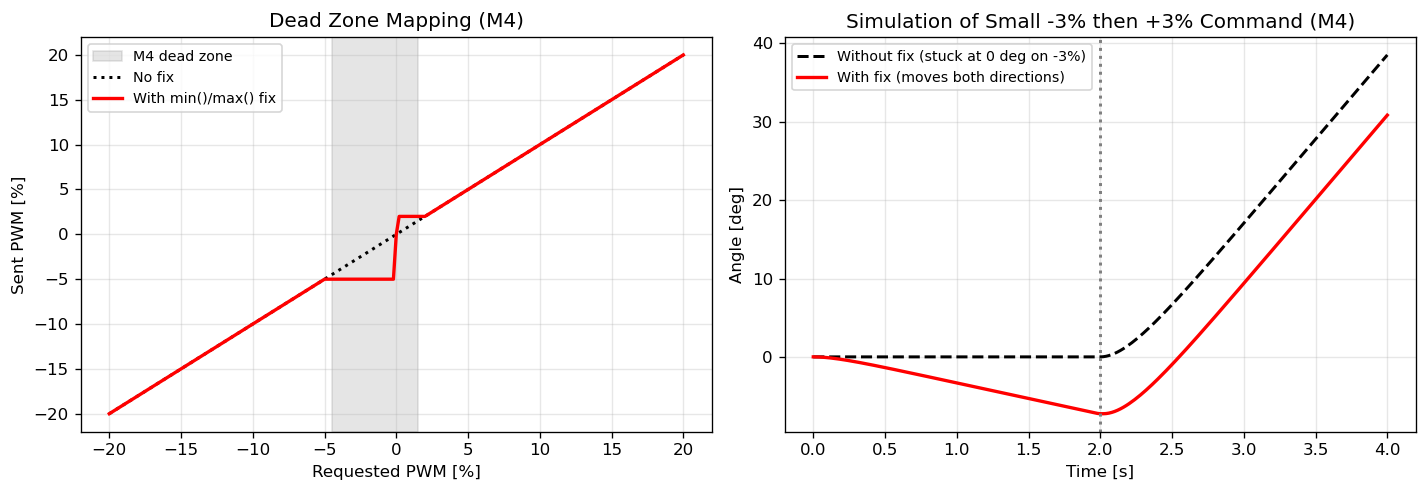

In [7]:
def read_deadzone(file_path):
    raw = np.loadtxt(file_path, delimiter=',')
    ang, t_ms, pwm = raw[:, 0], raw[:, 1], raw[:, 2]
    cuts = np.where(np.diff(pwm) != 0)[0] + 1
    pwms, degs = [], []
    for idx in np.split(np.arange(len(pwm)), cuts):
        p = int(pwm[idx[0]])
        if p != 0:
            pwms.append(p)
            degs.append(ang[idx[-1]] - ang[idx[0]])
    return np.array(pwms), np.array(degs)

dz_pwm_m3, dz_deg_m3 = read_deadzone(get_file('deadzone_M3'))
dz_pwm_m4, dz_deg_m4 = read_deadzone(get_file('deadzone_M4'))

print("M4 deadzone sweep (-6% to +4%):")
for p, d in zip(dz_pwm_m4, dz_deg_m4):
    if -6 <= p <= 4:
        print(f"  PWM {p:+3d}% -> {d:+6.1f} deg {'(stuck)' if abs(d) <= 2 else '(moving)'}")

def fix_deadzone(pwm, dz_fwd=2.0, dz_bwd=5.0):
    if pwm > 0:
        return min(100.0, max(pwm, dz_fwd))
    elif pwm < 0:
        return max(-100.0, min(pwm, -dz_bwd))
    return 0.0

print("\nExamples:")
for cmd in [-30, -3, -1, 0, 1, 3, 30]:
    print(f"  input {cmd:+3d}% -> sent {fix_deadzone(cmd):+6.1f}%")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))

cmds = np.linspace(-20, 20, 201)
ax1.axvspan(-4.5, 1.5, color='gray', alpha=0.2, label='M4 dead zone')
ax1.plot(cmds, cmds, 'k:', label='No fix')
ax1.plot(cmds, [fix_deadzone(c) for c in cmds], 'r-', lw=2.0, label='With min()/max() fix')
ax1.set_title('Dead Zone Mapping (M4)')
ax1.set_xlabel('Requested PWM [%]')
ax1.set_ylabel('Sent PWM [%]')
ax1.legend(fontsize=8.5)

# Test a small command: -3% for 2s then +3% for 2s
t_test = np.linspace(0, 4.0, 201)
pwm_cmd = np.where(t_test < 2.0, -3.0, 3.0)
u_raw = (pwm_cmd / 100.0) * U_battery
u_fix = (np.array([fix_deadzone(c) for c in pwm_cmd]) / 100.0) * U_battery

_, th_raw = simulate_motor(t_test, u_raw, ch_M4['Tm_f'], ch_M4['Tm_b'], ch_M4['ke_f'], ch_M4['ke_b'], Uc_fwd=0.12, Uc_bwd=0.53)
_, th_fix = simulate_motor(t_test, u_fix, ch_M4['Tm_f'], ch_M4['Tm_b'], ch_M4['ke_f'], ch_M4['ke_b'], Uc_fwd=0.12, Uc_bwd=0.53)

ax2.plot(t_test, th_raw * 180 / np.pi, 'k--', label='Without fix (stuck at 0 deg on -3%)')
ax2.plot(t_test, th_fix * 180 / np.pi, 'r-', lw=2.0, label='With fix (moves both directions)')
ax2.axvline(2.0, color='gray', linestyle=':')
ax2.set_title('Simulation of Small -3% then +3% Command (M4)')
ax2.set_xlabel('Time [s]')
ax2.set_ylabel('Angle [deg]')
ax2.legend(fontsize=8.5)

plt.tight_layout()
plt.show()


---
## 3. Coulomb Friction and Cancellation Voltage

Our basic first-order motor equation is:
$$T_m \omega' + \omega = \frac{u}{k_e}$$

When we include dry **Coulomb friction**, a constant torque always opposes the direction of rotation. In voltage units, this acts like losing a constant voltage $U_c$:
$$T_m \omega' + \omega = \frac{u - U_c \cdot \text{sign}(\omega)}{k_e}$$

### Finding $U_c$ and making friction disappear
From the M4 dead-zone test, `-4%` (`-0.47 V`) is stuck and `-5%` (`-0.59 V`) moves, so the backward friction voltage is right in the middle: $U_{c,\text{bwd}} \approx 0.53\text{ V}$ (`4.5%` PWM). Forward breaks free at `+1%` (`0.12 V`).

To make friction disappear, we add $U_c$ onto our desired voltage in the direction we want to move:
$$u_{\text{sent}} = u_{\text{des}} + U_c \cdot \text{sign}(u_{\text{des}})$$

When we put this back into the motor equation, $+U_c$ and $-U_c$ cancel out:
$$T_m \omega' + \omega = \frac{(u_{\text{des}} + U_c) - U_c}{k_e} = \frac{u_{\text{des}}}{k_e}$$

So the friction term drops out and the motor responds like the ideal equation again.


Measured friction voltage Uc:
  Motor M3: forward = 0.12 V (1.0%), backward = 0.12 V (1.0%)
  Motor M4: forward = 0.12 V (1.0%), backward = 0.53 V (4.5%)

Step RMSE vs ideal:  with friction = 0.438 rad/s  ->  cancelled = 0.073 rad/s
Chirp RMSE vs ideal: with friction = 0.243 rad/s  ->  cancelled = 0.148 rad/s


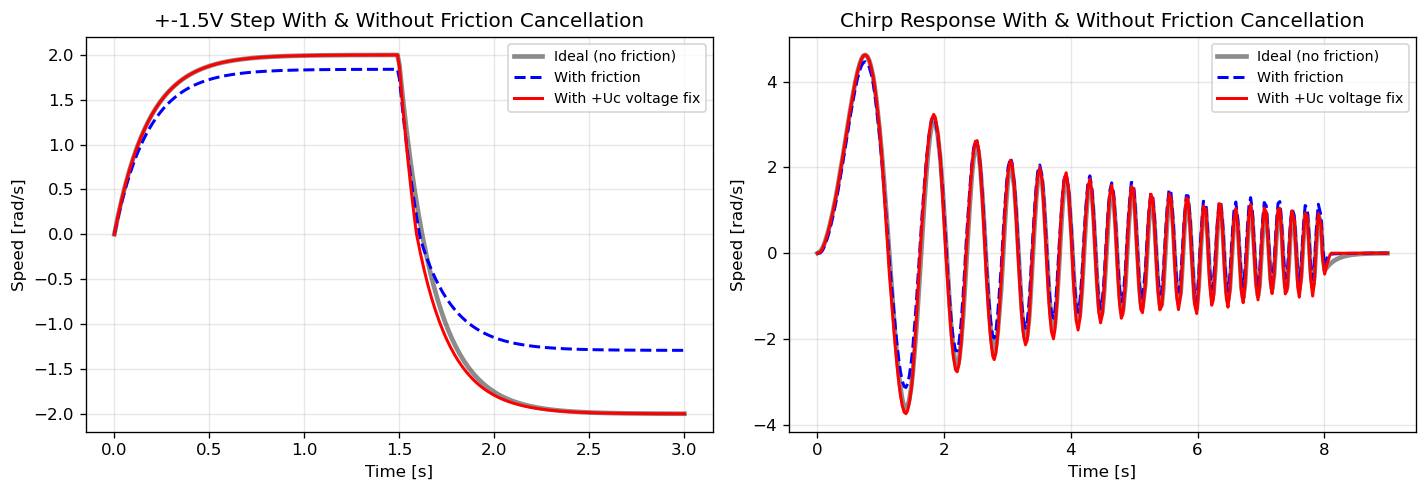

In [8]:
def get_breakaway_volts(pwms, degs):
    fwd_move = pwms[(pwms > 0) & (np.abs(degs) > 2)]
    bwd_move = pwms[(pwms < 0) & (np.abs(degs) > 2)]
    p_f = float(np.min(fwd_move)) if len(fwd_move) else 1.0
    p_b = float(np.max(bwd_move)) if len(bwd_move) else -1.0
    bwd_stuck = pwms[(pwms < 0) & (np.abs(degs) <= 2)]
    p_b_eff = 0.5 * (abs(float(np.min(bwd_stuck))) + abs(p_b)) if len(bwd_stuck) else abs(p_b)
    return round((p_f / 100.0) * U_battery, 2), round((p_b_eff / 100.0) * U_battery, 2)

Uc_m3_f, Uc_m3_b = get_breakaway_volts(dz_pwm_m3, dz_deg_m3)
Uc_m4_f, Uc_m4_b = get_breakaway_volts(dz_pwm_m4, dz_deg_m4)

print(f"Measured friction voltage Uc:")
print(f"  Motor M3: forward = {Uc_m3_f:.2f} V ({Uc_m3_f/U_battery*100:.1f}%), backward = {Uc_m3_b:.2f} V ({Uc_m3_b/U_battery*100:.1f}%)")
print(f"  Motor M4: forward = {Uc_m4_f:.2f} V ({Uc_m4_f/U_battery*100:.1f}%), backward = {Uc_m4_b:.2f} V ({Uc_m4_b/U_battery*100:.1f}%)")

def cancel_friction(u_des, Uc_fwd=0.12, Uc_bwd=0.53, U_max=11.7):
    if u_des > 0:
        return min(U_max, u_des + Uc_fwd)
    elif u_des < 0:
        return max(-U_max, u_des - Uc_bwd)
    return 0.0

# Test on a +-1.5V step and a chirp signal (M4)
Tm_m4, ke_m4 = 0.18, 0.75
t_s = np.linspace(0, 3.0, 301)
u_step = np.where(t_s < 1.5, 1.5, -1.5)
u_step_comp = np.array([cancel_friction(u, Uc_m4_f, Uc_m4_b, U_battery) for u in u_step])

w_ideal, _ = simulate_motor(t_s, u_step,      Tm_m4, Tm_m4, ke_m4, ke_m4, 0.0, 0.0)
w_fric,  _ = simulate_motor(t_s, u_step,      Tm_m4, Tm_m4, ke_m4, ke_m4, Uc_m4_f, Uc_m4_b)
w_canc,  _ = simulate_motor(t_s, u_step_comp, Tm_m4, Tm_m4, ke_m4, ke_m4, Uc_m4_f, Uc_m4_b)

t_c = ch_M4['t']
u_ch = 4.0 * (ch_M4['pwm'] / 60.0)
u_ch_comp = np.array([cancel_friction(u, Uc_m4_f, Uc_m4_b, U_battery) for u in u_ch])

wc_ideal, _ = simulate_motor(t_c, u_ch,      Tm_m4, Tm_m4, ke_m4, ke_m4, 0.0, 0.0)
wc_fric,  _ = simulate_motor(t_c, u_ch,      Tm_m4, Tm_m4, ke_m4, ke_m4, Uc_m4_f, Uc_m4_b)
wc_canc,  _ = simulate_motor(t_c, u_ch_comp, Tm_m4, Tm_m4, ke_m4, ke_m4, Uc_m4_f, Uc_m4_b)

print(f"\nStep RMSE vs ideal:  with friction = {rmse(w_ideal, w_fric):.3f} rad/s  ->  cancelled = {rmse(w_ideal, w_canc):.3f} rad/s")
print(f"Chirp RMSE vs ideal: with friction = {rmse(wc_ideal, wc_fric):.3f} rad/s  ->  cancelled = {rmse(wc_ideal, wc_canc):.3f} rad/s")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
ax1.plot(t_s, w_ideal, 'k-', lw=2.8, alpha=0.45, label='Ideal (no friction)')
ax1.plot(t_s, w_fric,  'b--', label='With friction')
ax1.plot(t_s, w_canc,  'r-',  label='With +Uc voltage fix')
ax1.set_title('+-1.5V Step With & Without Friction Cancellation')
ax1.set_xlabel('Time [s]')
ax1.set_ylabel('Speed [rad/s]')
ax1.legend(fontsize=8.5)

ax2.plot(t_c, wc_ideal, 'k-', lw=2.8, alpha=0.45, label='Ideal (no friction)')
ax2.plot(t_c, wc_fric,  'b--', label='With friction')
ax2.plot(t_c, wc_canc,  'r-',  label='With +Uc voltage fix')
ax2.set_title('Chirp Response With & Without Friction Cancellation')
ax2.set_xlabel('Time [s]')
ax2.set_ylabel('Speed [rad/s]')
ax2.legend(fontsize=8.5)

plt.tight_layout()
plt.show()


---
## 4. Backward–Forward Asymmetry Compensation

Both motors spin faster forward than backward at the same PWM. For example, on M4 at $\pm 60\%$ PWM, forward reaches $+10.05\text{ rad/s}$ ($k_{e,\text{fwd}} \approx 0.70$) while backward only reaches $-9.20\text{ rad/s}$ ($k_{e,\text{bwd}} \approx 0.76$), and backward also has larger friction ($0.53\text{ V}$ vs $0.12\text{ V}$). Because of this, in the square wave test (`square_M4`) the wheel drifted to $+72^\circ$ instead of returning to $0^\circ$.

### The idea and why it works
We want $+u$ and $-u$ to give the **same speed magnitude**. Instead of boosting the weaker side (which would hit the `100%` limit early), we match the faster side down to the slower side:
1. Pick $k_{e,\text{target}} = \max(k_{e,\text{fwd}}, k_{e,\text{bwd}})$.
2. Multiply the voltage by $\frac{k_{e,\text{dir}}}{k_{e,\text{target}}}$ so both directions have the same slope.
3. Add the directional friction voltage $U_{c,\text{dir}}$ so the starting offset is also removed.

When substituted into the motor model, both $k_{e,\text{dir}}$ and $U_{c,\text{dir}}$ cancel out, leaving the same symmetric speed in both directions.


M4 examples (ke_fwd=0.698, ke_bwd=0.763):
  requested -60% -> sent -64.53%
  requested -30% -> sent -34.53%
  requested +30% -> sent +28.48%
  requested +60% -> sent +55.93%

Speed at +-60%: before = 9.88 vs 8.50 rad/s | after = 9.20 vs 9.20 rad/s
Round-trip final angle (target 0 deg): before = +166.3 deg -> after = +9.3 deg


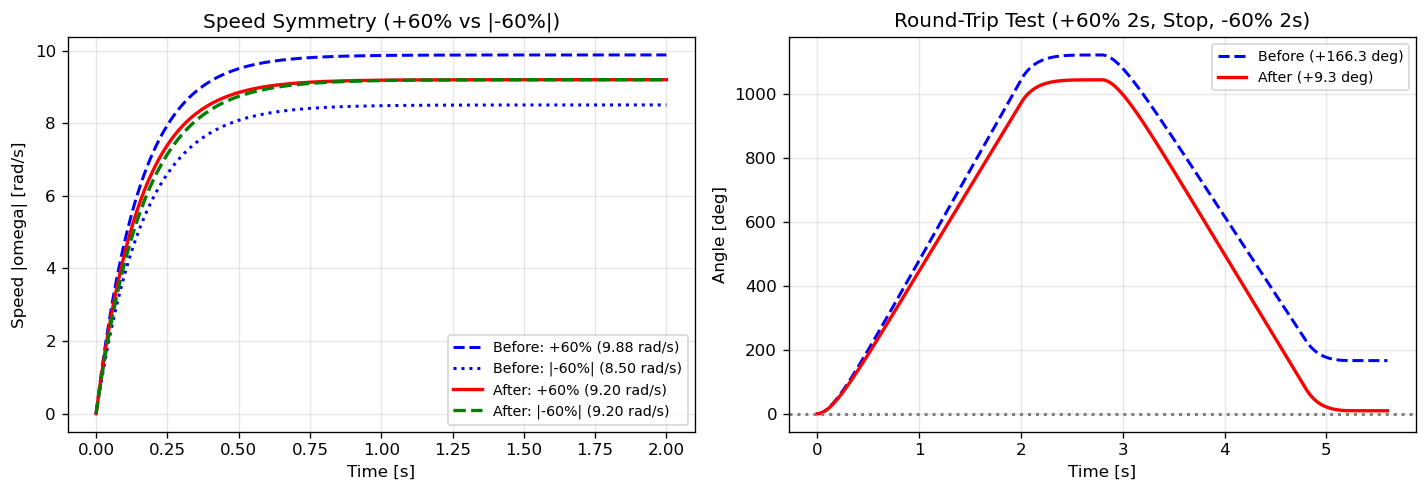

In [9]:
def compensate_asymmetry(pwm_des, ke_fwd, ke_bwd, Uc_fwd, Uc_bwd, U_batt=11.7):
    if pwm_des == 0:
        return 0.0
    ke_target = max(ke_fwd, ke_bwd)
    u_des = (pwm_des / 100.0) * U_batt

    if pwm_des > 0:
        u_cmd = (ke_fwd / ke_target) * u_des + Uc_fwd
    else:
        u_cmd = (ke_bwd / ke_target) * u_des - Uc_bwd

    return max(-100.0, min(100.0, (u_cmd / U_batt) * 100.0))

m4_ke_f = float(df_step_M4.loc[df_step_M4['PWM'] == 60, 'ke'].values[0])
m4_ke_b = float(df_step_M4.loc[df_step_M4['PWM'] == -60, 'ke'].values[0])
m4_Tm_f, m4_Tm_b = sq_M4['Tm_f'], sq_M4['Tm_b']

print(f"M4 examples (ke_fwd={m4_ke_f:.3f}, ke_bwd={m4_ke_b:.3f}):")
for p in [-60, -30, 30, 60]:
    print(f"  requested {p:+3d}% -> sent {compensate_asymmetry(p, m4_ke_f, m4_ke_b, Uc_m4_f, Uc_m4_b, U_battery):+6.2f}%")

# Test 1: +-60% step speed symmetry
t_st = np.linspace(0, 2.0, 201)
w_p_raw, _ = simulate_motor(t_st, np.full_like(t_st,  60/100*U_battery), m4_Tm_f, m4_Tm_b, m4_ke_f, m4_ke_b, Uc_m4_f, Uc_m4_b)
w_n_raw, _ = simulate_motor(t_st, np.full_like(t_st, -60/100*U_battery), m4_Tm_f, m4_Tm_b, m4_ke_f, m4_ke_b, Uc_m4_f, Uc_m4_b)

p_p_fix = compensate_asymmetry( 60, m4_ke_f, m4_ke_b, Uc_m4_f, Uc_m4_b, U_battery)
p_n_fix = compensate_asymmetry(-60, m4_ke_f, m4_ke_b, Uc_m4_f, Uc_m4_b, U_battery)
w_p_fix, _ = simulate_motor(t_st, np.full_like(t_st, p_p_fix/100*U_battery), m4_Tm_f, m4_Tm_b, m4_ke_f, m4_ke_b, Uc_m4_f, Uc_m4_b)
w_n_fix, _ = simulate_motor(t_st, np.full_like(t_st, p_n_fix/100*U_battery), m4_Tm_f, m4_Tm_b, m4_ke_f, m4_ke_b, Uc_m4_f, Uc_m4_b)

# Test 2: Forward 2s (+60%) -> Stop 0.8s -> Backward 2s (-60%) -> Stop 0.8s
t_rt = np.linspace(0, 5.6, 561)
pwm_rt = np.where(t_rt < 2.0, 60.0, np.where(t_rt < 2.8, 0.0, np.where(t_rt < 4.8, -60.0, 0.0)))
u_rt_raw = pwm_rt / 100.0 * U_battery
u_rt_fix = np.array([compensate_asymmetry(p, m4_ke_f, m4_ke_b, Uc_m4_f, Uc_m4_b, U_battery) for p in pwm_rt]) / 100.0 * U_battery

_, th_rt_raw = simulate_motor(t_rt, u_rt_raw, m4_Tm_f, m4_Tm_b, m4_ke_f, m4_ke_b, Uc_m4_f, Uc_m4_b)
_, th_rt_fix = simulate_motor(t_rt, u_rt_fix, m4_Tm_f, m4_Tm_b, m4_ke_f, m4_ke_b, Uc_m4_f, Uc_m4_b)

print(f"\nSpeed at +-60%: before = {w_p_raw[-1]:.2f} vs {abs(w_n_raw[-1]):.2f} rad/s | after = {w_p_fix[-1]:.2f} vs {abs(w_n_fix[-1]):.2f} rad/s")
print(f"Round-trip final angle (target 0 deg): before = {th_rt_raw[-1]*180/np.pi:+.1f} deg -> after = {th_rt_fix[-1]*180/np.pi:+.1f} deg")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
ax1.plot(t_st, w_p_raw, 'b--', label=f'Before: +60% ({w_p_raw[-1]:.2f} rad/s)')
ax1.plot(t_st, np.abs(w_n_raw), 'b:', label=f'Before: |-60%| ({abs(w_n_raw[-1]):.2f} rad/s)')
ax1.plot(t_st, w_p_fix, 'r-', lw=2.0, label=f'After: +60% ({w_p_fix[-1]:.2f} rad/s)')
ax1.plot(t_st, np.abs(w_n_fix), 'g--', lw=2.0, label=f'After: |-60%| ({abs(w_n_fix[-1]):.2f} rad/s)')
ax1.set_title('Speed Symmetry (+60% vs |-60%|)')
ax1.set_xlabel('Time [s]')
ax1.set_ylabel('Speed |omega| [rad/s]')
ax1.legend(fontsize=8.5)

ax2.plot(t_rt, th_rt_raw * 180 / np.pi, 'b--', label=f'Before ({th_rt_raw[-1]*180/np.pi:+.1f} deg)')
ax2.plot(t_rt, th_rt_fix * 180 / np.pi, 'r-', lw=2.0, label=f'After ({th_rt_fix[-1]*180/np.pi:+.1f} deg)')
ax2.axhline(0, color='gray', linestyle=':')
ax2.set_title('Round-Trip Test (+60% 2s, Stop, -60% 2s)')
ax2.set_xlabel('Time [s]')
ax2.set_ylabel('Angle [deg]')
ax2.legend(fontsize=8.5)

plt.tight_layout()
plt.show()
